<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 6: Scorecard creation

This notebook follows `05_grouping_Screening.ipynb`. We take our 12 final characteristics from Step 5, with the same bins and the same 70/30 train/test split, and turn them into a points-based scorecard with `scorecardpy` and logistic regression, as in the Week 11 lab.

We first build the scorecard on a reference scale of 600 points at the training odds, with PDO 20. `07_scorecard analysis.ipynb` loads the model we save at the end of this notebook and sets the cutoff and final scale from our profit analysis.

In [1]:
# ignore scorecardpy compatibility warnings
import warnings
warnings.filterwarnings('ignore')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model, metrics
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
import scorecardpy as sc
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 80

## 6.1 Business context

The scorecard estimates the probability of default (PD) for the **Home Improvement Loan** segment, which is home owners (`FLAG_OWN_REALTY = 'Y'`) aged 18 or over with positive income.

The earlier notebooks:

1. selected the customer segment (Step 0)
2. flattened the bureau data and merged it with the application data (Steps 1 and 2)
3. engineered new characteristics (Steps 1 and 2)
4. explored and prepared the data (Steps 3 and 4)
5. fine-classed and screened the characteristics on WOE and IV, then coarse-classed them into monotonic groups (Step 5)
6. picked the 12 final characteristics (Step 5)

This step combines them into one logistic regression model and turns the model into a scorecard:

> Raw value → bin → WOE → logistic regression → points per bin → total score

`TARGET = 1` is a bad borrower (defaulted) and `TARGET = 0` is a good one. A higher score means lower risk.

**WOE sign.** Step 5 defines WOE as `ln(% of goods / % of bads)`. scorecardpy flips it to `ln(% of bads / % of goods)`, so a higher WOE means a riskier group and the coefficients come out positive. The bins are identical and the points are the same either way, because the coefficient flips sign along with the WOE.

## 6.2 Load the data

`data/final_characteristics.csv` from Step 5 has `SK_ID_CURR`, `TARGET` and the raw values of our 12 final characteristics.

In [2]:
final = pd.read_csv('data/final_characteristics.csv')

ID, TARGET = 'SK_ID_CURR', 'TARGET'
X_COLS = ['EMPLOYMENT_YEARS', 'CREDIT_TO_GOODS_RATIO', 'ACTIVE_LOAN_RATIO',
          'MOST_RECENT_CREDIT_AGE', 'OCCUPATION_TYPE', 'OLDEST_CREDIT_AGE', 'ACTIVE_LOAN_COUNT',
          'NAME_INCOME_TYPE', 'DEBT_TO_CREDIT_RATIO', 'BUREAU_DEBT_TO_INCOME', 'NAME_EDUCATION_TYPE',
          'MICROLOAN_COUNT']

print('Applicants:', f'{len(final):,}', '| Characteristics:', len(X_COLS))
print('Good borrowers (TARGET = 0):', f'{(final[TARGET] == 0).sum():,}')
print('Bad borrowers (TARGET = 1):', f'{(final[TARGET] == 1).sum():,}')
print('Overall bad rate:', f'{final[TARGET].mean():.2%}')

Applicants: 213,312 | Characteristics: 12
Good borrowers (TARGET = 0): 196,329
Bad borrowers (TARGET = 1): 16,983
Overall bad rate: 7.96%


## 6.3 Train/test split

We reuse the split from Step 5 (`data/train_test_split.csv`, `sc.split_df`, 70/30, seed 186, stratified on `TARGET`). Our bins and WOE values were fitted on that training sample, so a new split would leak some of those applicants into the test set.

We keep the test sample aside until the final check in 6.11.

In [3]:
split_ids = pd.read_csv('data/train_test_split.csv')
data = final.merge(split_ids, on=ID, how='left', validate='one_to_one')
assert data['SAMPLE'].notnull().all()

train = data[data['SAMPLE'] == 'train'].drop(columns='SAMPLE').reset_index(drop=True)
test = data[data['SAMPLE'] == 'test'].drop(columns='SAMPLE').reset_index(drop=True)

split_summary = pd.DataFrame({'Applicants': [len(train), len(test)],
                              'Bads': [int(train[TARGET].sum()), int(test[TARGET].sum())]}, index=['Train', 'Test'])
split_summary['Share'] = split_summary['Applicants'] / len(final)
split_summary['Bad rate'] = split_summary['Bads'] / split_summary['Applicants']
display(split_summary.style.format({'Applicants': '{:,}', 'Bads': '{:,}', 'Share': '{:.1%}', 'Bad rate': '{:.2%}'}))

assert set(train[ID]).isdisjoint(test[ID]) and len(train) + len(test) == len(final)
print('No SK_ID_CURR appears in both samples; every applicant is in exactly one sample')

,Applicants,Bads,Share,Bad rate
Train,"149,318","11,888",70.0%,7.96%
Test,"63,994","5,095",30.0%,7.96%


No SK_ID_CURR appears in both samples; every applicant is in exactly one sample


## 6.4 WOE encoding

### 6.4.1 Convert the Step 5 bins to scorecardpy format

We pass our Step 5 groups (`data/coarse_classing_bins.json`) into `sc.woebin` as a `breaks_list`, so scorecardpy uses them as they are instead of searching for new ones. Our Step 5 bins are right-closed and scorecardpy bins are left-closed, so we nudge each edge up slightly to keep values that sit exactly on an edge in the same group.

In [4]:
with open('data/coarse_classing_bins.json') as f:
    approved_bins = json.load(f)
print('Approved bins fitted on:', approved_bins['fitted_on'])
print('Approved on:', approved_bins['approved'])
assert set(approved_bins['woe']) == set(X_COLS)


def left_closed_break(variable, e):
    # smallest clean break above e with no observed value in (e, break]
    observed = final[variable].dropna()
    if (observed % 1 == 0).all():
        return e + 0.5
    above = np.sort(observed[observed > e].unique())
    for step in [1e-6, 1e-7, 1e-8, 1e-9, 1e-10]:
        if len(above) == 0 or above[0] > e + step:
            return round(e + step, 12)
    raise ValueError(f'No break found for {variable} at {e}')

breaks_list = {}
for variable, edges in approved_bins['numeric_edges_right_closed'].items():
    breaks_list[variable] = [left_closed_break(variable, e) for e in edges if e is not None]
for variable, position in approved_bins['missing_merged_into_group_position'].items():
    if position < len(breaks_list[variable]):
        breaks_list[variable][position] = f'{breaks_list[variable][position]}%,%missing'
    else:
        breaks_list[variable].append('inf%,%missing')
for variable, groups in approved_bins['category_groups'].items():
    breaks_list[variable] = ['%,%'.join(categories) for categories in groups.values()]

display(pd.DataFrame({'Step 5 edges (right-closed) or groups': {v: approved_bins['numeric_edges_right_closed'].get(v, list(approved_bins['category_groups'].get(v, {}))) for v in X_COLS},
                      'scorecardpy breaks_list': {v: breaks_list[v] for v in X_COLS}}))

Approved bins fitted on: training sample (sc.split_df ratio 0.7, seed 186; data/train_test_split.csv)
Approved on: 2026-10-30


,Step 5 edges (right-closed) or groups,scorecardpy breaks_list
EMPLOYMENT_YEARS,"[None, 2.5, 4, 7, 9, 15, None]","[2.500001, 4.000001, 7.000001, 9.000001, 15.000001]"
CREDIT_TO_GOODS_RATIO,"[None, 1.13, 1.2, 1.28, None]","[1.130001%,%missing, 1.200001, 1.280001]"
ACTIVE_LOAN_RATIO,"[None, 0.2, 0.34, 0.5, 0.67, None]","[0.200001, 0.340001, 0.500001, 0.670001]"
MOST_RECENT_CREDIT_AGE,"[None, 0.2, 0.7, 1.7, None]","[0.200001, 0.700001, 1.700001]"
OCCUPATION_TYPE,"[Office, professional and skilled, Sales, service and labour, Drivers, waiters and low-skill labour]","[Accountants%,%IT staff%,%HR staff%,%Managers%,%Secretaries%,%Core staff%,%Medicine staff%,%High skill tech staff%,%..."
OLDEST_CREDIT_AGE,"[None, 2, 3, 5, None]","[2.000001, 3.000001, 5.000001]"
ACTIVE_LOAN_COUNT,"[None, 0, 2, 3, None]","[0.5, 2.5, 3.5]"
NAME_INCOME_TYPE,"[Pensioner / State servant, Commercial associate / Businessman / Student, Working / Unemployed / Maternity leave]","[Pensioner%,%State servant, Commercial associate%,%Businessman%,%Student, Working%,%Unemployed%,%Maternity leave]"
DEBT_TO_CREDIT_RATIO,"[None, 0, 0.7, 0.8, 0.9, None]","[1e-07, 0.700001, 0.800001, 0.9000001]"
BUREAU_DEBT_TO_INCOME,"[None, 0, 1.7, 3.5, None]","[1e-06, 1.700001, 3.500001]"


### 6.4.2 Build the bins on the training sample

`sc.woebin` runs with the `breaks_list` on the training sample only. The bin tables below should match Step 5, with the WOE sign flipped.

In [5]:
bins = sc.woebin(train[X_COLS + [TARGET]], y=TARGET, x=X_COLS, breaks_list=breaks_list)

for variable in X_COLS:
    print(variable, ':')
    display(bins[variable][['variable', 'bin', 'count', 'count_distr', 'good', 'bad', 'badprob', 'woe', 'bin_iv', 'total_iv']])
    print('--' * 50)

[INFO] creating woe binning ...
Binning on 149318 rows and 13 columns in 00:00:13
EMPLOYMENT_YEARS :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,EMPLOYMENT_YEARS,missing,29563,0.197987,27998,1565,0.052938,-0.436662,0.031475,0.115544
1,EMPLOYMENT_YEARS,"[-inf,2.500001)",34969,0.234191,31017,3952,0.113014,0.387272,0.041339,0.115544
2,EMPLOYMENT_YEARS,"[2.500001,4.000001)",18752,0.125584,16887,1865,0.099456,0.244302,0.008307,0.115544
3,EMPLOYMENT_YEARS,"[4.000001,7.000001)",25113,0.168185,23020,2093,0.083343,0.049820,0.000426,0.115544
4,EMPLOYMENT_YEARS,"[7.000001,9.000001)",11622,0.077834,10785,837,0.072019,-0.108502,0.000876,0.115544
5,EMPLOYMENT_YEARS,"[9.000001,15.000001)",17721,0.118680,16656,1065,0.060098,-0.302211,0.009553,0.115544
6,EMPLOYMENT_YEARS,"[15.000001,inf)",11578,0.077539,11067,511,0.044135,-0.627768,0.023569,0.115544


----------------------------------------------------------------------------------------------------
CREDIT_TO_GOODS_RATIO :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,CREDIT_TO_GOODS_RATIO,"[-inf,1.130001)%,%missing",79330,0.531282,74342,4988,0.062877,-0.254056,0.030833,0.08326
1,CREDIT_TO_GOODS_RATIO,"[1.130001,1.200001)",37634,0.252039,34553,3081,0.081867,0.030345,0.000235,0.08326
2,CREDIT_TO_GOODS_RATIO,"[1.200001,1.280001)",17460,0.116932,15566,1894,0.108477,0.341187,0.015714,0.08326
3,CREDIT_TO_GOODS_RATIO,"[1.280001,inf)",14894,0.099747,12969,1925,0.129247,0.539949,0.036479,0.08326


----------------------------------------------------------------------------------------------------
ACTIVE_LOAN_RATIO :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,ACTIVE_LOAN_RATIO,missing,21981,0.147209,19827,2154,0.097994,0.227867,8.413153e-03,0.089794
1,ACTIVE_LOAN_RATIO,"[-inf,0.200001)",35789,0.239683,33891,1898,0.053033,-0.434764,3.780215e-02,0.089794
2,ACTIVE_LOAN_RATIO,"[0.200001,0.340001)",26055,0.174493,24442,1613,0.061908,-0.270622,1.141145e-02,0.089794
3,ACTIVE_LOAN_RATIO,"[0.340001,0.500001)",30577,0.204778,28142,2435,0.079635,0.000269,1.480228e-08,0.089794
4,ACTIVE_LOAN_RATIO,"[0.500001,0.670001)",13271,0.088877,11915,1356,0.102178,0.274326,7.507191e-03,0.089794
5,ACTIVE_LOAN_RATIO,"[0.670001,inf)",21645,0.144959,19213,2432,0.112359,0.380712,2.466023e-02,0.089794


... (15 outputs left out)

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,NAME_EDUCATION_TYPE,"Higher education%,%Academic degree",35925,0.240594,34004,1921,0.053473,-0.426047,0.036570,0.046066
1,NAME_EDUCATION_TYPE,Incomplete higher,4580,0.030673,4207,373,0.081441,0.024659,0.000019,0.046066
2,NAME_EDUCATION_TYPE,"Secondary / secondary special%,%Lower secondary",108813,0.728733,99219,9594,0.088170,0.111394,0.009476,0.046066


----------------------------------------------------------------------------------------------------
MICROLOAN_COUNT :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,MICROLOAN_COUNT,missing,21981,0.147209,19827,2154,0.097994,0.227867,0.008413,0.028375
1,MICROLOAN_COUNT,"[-inf,0.5)",125585,0.841057,116176,9409,0.074921,-0.065854,0.003548,0.028375
2,MICROLOAN_COUNT,"[0.5,inf)",1752,0.011733,1427,325,0.185502,0.968081,0.016414,0.028375


----------------------------------------------------------------------------------------------------


### 6.4.3 Check the bins against Step 5

Each characteristic should have the same number of groups and the same IV as in Step 5, and every group's WOE should equal the Step 5 WOE with the sign flipped (scorecardpy convention).

In [6]:
def step5_order(variable):
    # Step 5 group labels in scorecardpy row order (scorecardpy lists a separate 'missing' row first)
    labels = list(approved_bins['woe'][variable])
    return (['Missing'] + [l for l in labels if l != 'Missing']) if 'Missing' in labels else labels

bin_check = []
for variable in X_COLS:
    b = bins[variable]
    labels = step5_order(variable)
    step5_woe = np.array([approved_bins['woe'][variable][l] for l in labels])
    same_groups = len(b) == len(labels)
    bin_check.append({
        'Characteristic': variable,
        'Step 5 groups': len(labels),
        'scorecardpy groups': len(b),
        'Step 5 coarse IV': approved_bins['coarse_iv'][variable],
        'scorecardpy IV': b['total_iv'].iloc[0],
        'Max |WOE difference| (sign flipped)': np.abs(b['woe'].values + step5_woe).max() if same_groups else np.nan,
    })
bin_check = pd.DataFrame(bin_check)
bin_check['Match'] = ((bin_check['Step 5 groups'] == bin_check['scorecardpy groups'])
                      & np.isclose(bin_check['Step 5 coarse IV'], bin_check['scorecardpy IV'], atol=1e-6)
                      & (bin_check['Max |WOE difference| (sign flipped)'] < 1e-6))
display(bin_check.set_index('Characteristic').style.format({'Step 5 coarse IV': '{:.6f}', 'scorecardpy IV': '{:.6f}',
                                                            'Max |WOE difference| (sign flipped)': '{:.1e}'}))
assert bin_check['Match'].all()
print(f'All {len(X_COLS)} characteristics: same groups, same IV and same WOE (sign flipped) as Step 5')

,Step 5 groups,scorecardpy groups,Step 5 coarse IV,scorecardpy IV,Max |WOE difference| (sign flipped),Match
Characteristic,,,,,,
EMPLOYMENT_YEARS,7,7,0.115544,0.115544,5.0e-07,True
CREDIT_TO_GOODS_RATIO,4,4,0.083260,0.083260,2.8e-07,True
ACTIVE_LOAN_RATIO,6,6,0.089794,0.089794,4.2e-07,True
MOST_RECENT_CREDIT_AGE,5,5,0.089021,0.089021,4.9e-07,True
OCCUPATION_TYPE,4,4,0.080592,0.080592,4.7e-07,True
OLDEST_CREDIT_AGE,5,5,0.073696,0.073696,2.9e-07,True
ACTIVE_LOAN_COUNT,5,5,0.057176,0.057176,4.8e-07,True
NAME_INCOME_TYPE,3,3,0.060456,0.060456,2.3e-07,True
DEBT_TO_CREDIT_RATIO,6,6,0.059952,0.059952,4.6e-07,True


All 12 characteristics: same groups, same IV and same WOE (sign flipped) as Step 5


### 6.4.4 Apply the WOE encoding

`sc.woebin_ply` replaces each raw value with the WOE of its bin. The training bins are applied to both samples.

In [7]:
train_predictors, test_predictors = train[X_COLS], test[X_COLS]
y_train, y_test = train[TARGET], test[TARGET]

WOE_COLS = [f'{c}_woe' for c in X_COLS]
train_woe = sc.woebin_ply(train_predictors, bins)[WOE_COLS]
test_woe = sc.woebin_ply(test_predictors, bins)[WOE_COLS]
train_woe.head()

[INFO] converting into woe values ...
[INFO] converting into woe values ...


,EMPLOYMENT_YEARS_woe,CREDIT_TO_GOODS_RATIO_woe,ACTIVE_LOAN_RATIO_woe,MOST_RECENT_CREDIT_AGE_woe,OCCUPATION_TYPE_woe,OLDEST_CREDIT_AGE_woe,ACTIVE_LOAN_COUNT_woe,NAME_INCOME_TYPE_woe,DEBT_TO_CREDIT_RATIO_woe,BUREAU_DEBT_TO_INCOME_woe,NAME_EDUCATION_TYPE_woe,MICROLOAN_COUNT_woe
0,0.387272,0.030345,-0.270622,0.115785,0.262227,-0.028730,-0.128312,0.193009,-0.156794,-0.027392,0.111394,-0.065854
1,0.387272,-0.254056,-0.434764,-0.240648,0.262227,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854
2,-0.108502,-0.254056,0.227867,0.227867,0.262227,0.227867,0.227867,0.193009,-0.060236,0.173033,0.111394,0.227867
3,0.049820,-0.254056,-0.270622,0.115785,0.262227,-0.028730,-0.128312,-0.420847,0.266158,0.077180,0.111394,-0.065854
4,0.387272,-0.254056,0.000269,-0.422299,-0.283986,-0.301032,-0.128312,-0.420847,-0.156794,-0.027392,-0.426047,-0.065854


## 6.5 Export the WOE-encoded data

`data/encoded.csv` has one row per applicant with `SK_ID_CURR`, `TARGET`, a WOE column for each of the 12 final characteristics and `DATA_SPLIT` (TRAIN or TEST). Step 7 reads it.

In [8]:
encoded = pd.concat([
    pd.concat([train[[ID, TARGET]], train_woe], axis=1).assign(DATA_SPLIT='TRAIN'),
    pd.concat([test[[ID, TARGET]], test_woe], axis=1).assign(DATA_SPLIT='TEST'),
]).sort_values(ID).reset_index(drop=True)
encoded.to_csv('data/encoded.csv', index=False)
print('Saved data/encoded.csv:', encoded.shape)
display(encoded.head())

Saved data/encoded.csv: (213312, 15)


,SK_ID_CURR,TARGET,EMPLOYMENT_YEARS_woe,CREDIT_TO_GOODS_RATIO_woe,ACTIVE_LOAN_RATIO_woe,MOST_RECENT_CREDIT_AGE_woe,OCCUPATION_TYPE_woe,OLDEST_CREDIT_AGE_woe,ACTIVE_LOAN_COUNT_woe,NAME_INCOME_TYPE_woe,DEBT_TO_CREDIT_RATIO_woe,BUREAU_DEBT_TO_INCOME_woe,NAME_EDUCATION_TYPE_woe,MICROLOAN_COUNT_woe,DATA_SPLIT
0,100002,1,0.387272,0.030345,-0.270622,0.115785,0.262227,-0.028730,-0.128312,0.193009,-0.156794,-0.027392,0.111394,-0.065854,TRAIN
1,100004,0,0.387272,-0.254056,-0.434764,-0.240648,0.262227,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854,TRAIN
2,100006,0,-0.108502,-0.254056,0.227867,0.227867,0.262227,0.227867,0.227867,0.193009,-0.060236,0.173033,0.111394,0.227867,TRAIN
3,100007,0,-0.108502,-0.254056,-0.434764,-0.422299,-0.283986,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854,TEST
4,100008,0,0.049820,-0.254056,-0.270622,0.115785,0.262227,-0.028730,-0.128312,-0.420847,0.266158,0.077180,0.111394,-0.065854,TRAIN


## 6.6 Logistic regression

### 6.6.1 Standard vs `class_weight='balanced'`

In Week 9 we used `class_weight='balanced'`. It can catch more bads at a given cutoff, but it inflates the predicted PDs: the model trains as if half the applicants were bad, so its PDs no longer match the real default rate.

We compare both options with 5-fold stratified cross-validation on the training sample, on two measures:

- ROC AUC, which shows how well the model ranks bads above goods
- the mean predicted PD against the actual training bad rate of 7.96%

Our score scale and the Step 7 profit analysis both use the PDs directly, so the PDs need to match reality. We keep the standard model unless the balanced one beats it on AUC by more than 0.005.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=186)
configs = {'Standard': dict(max_iter=1000),
           "class_weight='balanced'": dict(class_weight='balanced', max_iter=1000)}

cv_rows = []
for name, params in configs.items():
    model = linear_model.LogisticRegression(**params)
    auc = cross_validate(model, train_woe, y_train, cv=cv, scoring='roc_auc')['test_score'].mean()
    pd_oof = cross_val_predict(model, train_woe, y_train, cv=cv, method='predict_proba')[:, 1]
    cv_rows.append({'Configuration': name, 'CV ROC AUC': auc,
                    'Mean predicted PD': pd_oof.mean(), 'Actual bad rate': y_train.mean()})
cv_results = pd.DataFrame(cv_rows).set_index('Configuration')
display(cv_results.style.format({'CV ROC AUC': '{:.4f}', 'Mean predicted PD': '{:.2%}', 'Actual bad rate': '{:.2%}'}))

auc_gain = cv_results.loc["class_weight='balanced'", 'CV ROC AUC'] - cv_results.loc['Standard', 'CV ROC AUC']
LR_CONFIG = "class_weight='balanced'" if auc_gain > 0.005 else 'Standard'
print(f'AUC gain from class weighting: {auc_gain:+.4f}  ->  selected configuration: {LR_CONFIG}')

,CV ROC AUC,Mean predicted PD,Actual bad rate
Configuration,,,
Standard,0.6782,7.96%,7.96%
class_weight='balanced',0.6782,45.89%,7.96%


AUC gain from class weighting: +0.0001  ->  selected configuration: Standard


**What we found**

Both models rank applicants equally well, with a cross-validated AUC of 0.678. The difference is in the PDs. The balanced model predicts an average PD of 45.9%, almost six times the real bad rate of 7.96%. The standard model averages 7.96%, so **we use the standard model**.

### 6.6.2 Coefficient signs

With scorecardpy's WOE, a higher WOE means a riskier group. Every coefficient should therefore be positive, because moving to a riskier group should raise the predicted PD.

In [10]:
def coefficient_table(model, columns):
    t = pd.DataFrame({'Characteristic': [c.replace('_woe', '') for c in columns], 'Coefficient': model.coef_[0]})
    t['Sign'] = np.where(t['Coefficient'] > 0, '+', '-')
    t['Interpretation'] = np.where(t['Coefficient'] > 0, 'Expected: a riskier group (higher WOE) raises the predicted PD',
                                   'UNEXPECTED: a riskier group lowers the predicted PD - investigate')
    return t.set_index('Characteristic')

lr_all = linear_model.LogisticRegression(**configs[LR_CONFIG]).fit(train_woe, y_train)
display(coefficient_table(lr_all, WOE_COLS).style.format({'Coefficient': '{:+.4f}'}))
FLAGGED = [c.replace('_woe', '') for c, b in zip(WOE_COLS, lr_all.coef_[0]) if b < 0]
print('Unexpected (negative) coefficients:', FLAGGED)

,Coefficient,Sign,Interpretation
Characteristic,,,
EMPLOYMENT_YEARS,+0.6587,+,Expected: a riskier group (higher WOE) raises the predicted PD
CREDIT_TO_GOODS_RATIO,+0.8305,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_RATIO,+0.4112,+,Expected: a riskier group (higher WOE) raises the predicted PD
MOST_RECENT_CREDIT_AGE,+0.4082,+,Expected: a riskier group (higher WOE) raises the predicted PD
OCCUPATION_TYPE,+0.4598,+,Expected: a riskier group (higher WOE) raises the predicted PD
OLDEST_CREDIT_AGE,+0.3800,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_COUNT,+0.9686,+,Expected: a riskier group (higher WOE) raises the predicted PD
NAME_INCOME_TYPE,+0.2569,+,Expected: a riskier group (higher WOE) raises the predicted PD
DEBT_TO_CREDIT_RATIO,+1.0577,+,Expected: a riskier group (higher WOE) raises the predicted PD


Unexpected (negative) coefficients: ['BUREAU_DEBT_TO_INCOME']


### 6.6.3 Investigating the negative coefficient

On its own, every characteristic has a monotonic relationship with default in the right direction (Step 5). A coefficient can still turn negative in the combined model when a characteristic overlaps heavily with others. We run two checks:

1. which other WOE column the flagged characteristic is most correlated with
2. how the cross-validated AUC and the signs change when we refit without it

In [11]:
overlap = []
for v in FLAGGED:
    others = [c for c in WOE_COLS if c != f'{v}_woe']
    corr_all = train_woe[others].corrwith(train_woe[f'{v}_woe'])
    top = corr_all.abs().idxmax()
    overlap.append({'Characteristic': v, 'Most correlated WOE column': top.replace('_woe', ''),
                    'Correlation': corr_all[top]})
display(pd.DataFrame(overlap).set_index('Characteristic').style.format({'Correlation': '{:.3f}'}))

MODEL_X = [c for c in X_COLS if c not in FLAGGED]
MODEL_WOE = [f'{c}_woe' for c in MODEL_X]
variants = {f'All {len(X_COLS)}': WOE_COLS, **{f'Without {v}': [c for c in WOE_COLS if c != f'{v}_woe'] for v in FLAGGED}}
if len(FLAGGED) > 1:
    variants[f'Without all {len(FLAGGED)} flagged'] = MODEL_WOE
variant_rows = []
for name, cols in variants.items():
    m = linear_model.LogisticRegression(**configs[LR_CONFIG]).fit(train_woe[cols], y_train)
    auc = cross_validate(linear_model.LogisticRegression(**configs[LR_CONFIG]), train_woe[cols], y_train, cv=cv, scoring='roc_auc')['test_score'].mean()
    negative = {c.replace('_woe', ''): round(b, 3) for c, b in zip(cols, m.coef_[0]) if b < 0}
    variant_rows.append({'Model': name, 'Characteristics': len(cols), 'CV ROC AUC': auc,
                         'Negative coefficients': ', '.join(f'{k} ({v:+.3f})' for k, v in negative.items()) or 'none'})
display(pd.DataFrame(variant_rows).set_index('Model').style.format({'CV ROC AUC': '{:.4f}'}))

,Most correlated WOE column,Correlation
Characteristic,,
BUREAU_DEBT_TO_INCOME,ACTIVE_LOAN_COUNT,0.684


,Characteristics,CV ROC AUC,Negative coefficients
Model,,,
All 12,12,0.6782,BUREAU_DEBT_TO_INCOME (-0.798)
Without BUREAU_DEBT_TO_INCOME,11,0.6765,none


**What we found**

`BUREAU_DEBT_TO_INCOME` gets a negative coefficient (-0.80), even though on its own its risk rises with debt. The cause is its overlap with `ACTIVE_LOAN_COUNT` (WOE correlation 0.68). More active loans usually means more debt, so once the model knows the loan count, the leftover effect of debt-to-income comes out reversed.

Dropping it fixes the sign and costs only 0.0017 in cross-validated AUC (0.6782 to 0.6765). Keeping it would give applicants with no existing debt the fewest points, which makes no business sense. **We drop it from the regression**, but keep it in `final_characteristics.csv` and `encoded.csv`.

### 6.6.4 Final model

We fit the final model on the training WOE values of the 11 remaining characteristics, with the set-up from 6.6.1.

In [12]:
REMOVED_FOR_SIGN = FLAGGED
X_train, X_test = train_woe[MODEL_WOE], test_woe[MODEL_WOE]

# fit the final logistic regression on the training WOE values only 
lr = linear_model.LogisticRegression(**configs[LR_CONFIG])
lr.fit(X_train, y_train)
coefficients = pd.Series(np.concatenate([lr.intercept_, lr.coef_[0]]), index=np.concatenate([['intercept'], lr.feature_names_in_]))
assert len(lr.feature_names_in_) == len(X_COLS) - len(REMOVED_FOR_SIGN)
pd_train = lr.predict_proba(X_train)[:, 1]
pd_test = lr.predict_proba(X_test)[:, 1]
print(f'Model characteristics: {len(MODEL_X)} | excluded from the regression (coefficient sign): {", ".join(REMOVED_FOR_SIGN) or "none"}')
coefficients

Model characteristics: 11 | excluded from the regression (coefficient sign): BUREAU_DEBT_TO_INCOME


intercept                    -2.449110
EMPLOYMENT_YEARS_woe          0.678715
CREDIT_TO_GOODS_RATIO_woe     0.830037
ACTIVE_LOAN_RATIO_woe         0.321283
MOST_RECENT_CREDIT_AGE_woe    0.376583
OCCUPATION_TYPE_woe           0.452568
OLDEST_CREDIT_AGE_woe         0.380649
ACTIVE_LOAN_COUNT_woe         0.570101
NAME_INCOME_TYPE_woe          0.248463
DEBT_TO_CREDIT_RATIO_woe      0.811177
NAME_EDUCATION_TYPE_woe       0.836296
MICROLOAN_COUNT_woe           0.220718
dtype: float64

#### Fitted regression formula

In [13]:
terms = [f'{b:+.4f} x {c}' for c, b in zip(X_train.columns, lr.coef_[0])]
formula = 'Logit(PD) = ' + f'{lr.intercept_[0]:.4f}\n            ' + '\n            '.join(terms)
print(formula)
print('\nPD = 1 / (1 + exp(-Logit(PD)))')

Logit(PD) = -2.4491
            +0.6787 x EMPLOYMENT_YEARS_woe
            +0.8300 x CREDIT_TO_GOODS_RATIO_woe
            +0.3213 x ACTIVE_LOAN_RATIO_woe
            +0.3766 x MOST_RECENT_CREDIT_AGE_woe
            +0.4526 x OCCUPATION_TYPE_woe
            +0.3806 x OLDEST_CREDIT_AGE_woe
            +0.5701 x ACTIVE_LOAN_COUNT_woe
            +0.2485 x NAME_INCOME_TYPE_woe
            +0.8112 x DEBT_TO_CREDIT_RATIO_woe
            +0.8363 x NAME_EDUCATION_TYPE_woe
            +0.2207 x MICROLOAN_COUNT_woe

PD = 1 / (1 + exp(-Logit(PD)))


#### Coefficient table

In [14]:
display(coefficient_table(lr, MODEL_WOE).style.format({'Coefficient': '{:+.4f}'}))
print(f'Intercept: {lr.intercept_[0]:+.4f}  ->  PD of an applicant whose WOE is 0 on every characteristic: {1 / (1 + np.exp(-lr.intercept_[0])):.2%}')

,Coefficient,Sign,Interpretation
Characteristic,,,
EMPLOYMENT_YEARS,+0.6787,+,Expected: a riskier group (higher WOE) raises the predicted PD
CREDIT_TO_GOODS_RATIO,+0.8300,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_RATIO,+0.3213,+,Expected: a riskier group (higher WOE) raises the predicted PD
MOST_RECENT_CREDIT_AGE,+0.3766,+,Expected: a riskier group (higher WOE) raises the predicted PD
OCCUPATION_TYPE,+0.4526,+,Expected: a riskier group (higher WOE) raises the predicted PD
OLDEST_CREDIT_AGE,+0.3806,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_COUNT,+0.5701,+,Expected: a riskier group (higher WOE) raises the predicted PD
NAME_INCOME_TYPE,+0.2485,+,Expected: a riskier group (higher WOE) raises the predicted PD
DEBT_TO_CREDIT_RATIO,+0.8112,+,Expected: a riskier group (higher WOE) raises the predicted PD


Intercept: -2.4491  ->  PD of an applicant whose WOE is 0 on every characteristic: 7.95%


**What we found**

All 11 coefficients are positive, so a riskier bin always raises the predicted PD.

Coefficients range from 0.22 (`MICROLOAN_COUNT`) to 0.84 (`NAME_EDUCATION_TYPE`). A coefficient near 1 means the model uses the characteristic at about its stand-alone strength. A smaller one means other characteristics already cover part of its information, for example `ACTIVE_LOAN_COUNT` for `ACTIVE_LOAN_RATIO`.

The intercept of -2.45 gives a PD of about 7.95% for an applicant with a WOE of 0 on every characteristic, which is roughly the average applicant.

## 6.7 Scorecard at the reference scale

`sc.scorecard` combines our bins and fitted model into points. We start from a reference scale of 600 points at the training sample's own bad:good odds, with PDO 20 and the base points spread evenly across characteristics (`basepoints_eq0=True`). In Step 7 we pick the cutoff and final scale from the profit analysis.

Points are rounded to whole numbers (the scorecardpy default).

In [15]:
POINTS0, PDO = 600, 20
ODDS0_REFERENCE = y_train.sum() / (len(y_train) - y_train.sum())     # the training sample's own bad:good odds
TARGET_BAD_RATE = 0.05                    # original cutoff rule used in Step 7: approved bad rate at most 5%
print(f'Reference odds: {ODDS0_REFERENCE:.5f} = 1 : {1 / ODDS0_REFERENCE:.2f} (training bad rate {y_train.mean():.2%})')

card = sc.scorecard(bins, lr, X_train.columns, points0=POINTS0, odds0=ODDS0_REFERENCE, pdo=PDO, basepoints_eq0=True)
print('Separate base points line:', card['basepoints']['points'].iloc[0])
assert set(card) - {'basepoints'} == set(MODEL_X)

coef_by_var = dict(zip(MODEL_X, lr.coef_[0]))

def full_scorecard(card):
    t = pd.concat([card[v][['variable', 'bin', 'points']].merge(bins[v][['bin', 'count', 'badprob', 'woe']], on='bin', how='left')
                   for v in MODEL_X], ignore_index=True)
    t['coefficient'] = t['variable'].map(coef_by_var)
    t = t[['variable', 'bin', 'count', 'badprob', 'woe', 'coefficient', 'points']]
    t.columns = ['Characteristic', 'Bin', 'Training applicants', 'Bad rate', 'WOE (scorecardpy)', 'Regression coefficient', 'Points']
    assert t['Points'].notnull().all() and set(t['Characteristic']) == set(MODEL_X)
    assert len(t) == sum(len(bins[v]) for v in MODEL_X)
    return t

card_fmt = {'Training applicants': '{:,}', 'Bad rate': '{:.2%}', 'WOE (scorecardpy)': '{:+.4f}', 'Regression coefficient': '{:+.4f}', 'Points': '{:.0f}'}
scorecard_table = full_scorecard(card)
display(scorecard_table.style.format(card_fmt).hide(axis='index'))
points_range = scorecard_table.groupby('Characteristic', sort=False)['Points'].agg(['min', 'max'])
points_range['Range (max - min)'] = points_range['max'] - points_range['min']
display(points_range.sort_values('Range (max - min)', ascending=False).rename(columns={'min': 'Lowest points', 'max': 'Highest points'}))
print(f'{len(MODEL_X)} characteristics, {len(scorecard_table)} bins | possible scores: {points_range["min"].sum():.0f} to {points_range["max"].sum():.0f}')

Reference odds: 0.08650 = 1 : 11.56 (training bad rate 7.96%)
Separate base points line: 0


Characteristic,Bin,Training applicants,Bad rate,WOE (scorecardpy),Regression coefficient,Points
EMPLOYMENT_YEARS,missing,"29,563",5.29%,-0.4367,+0.6787,63
EMPLOYMENT_YEARS,"[-inf,2.500001)","34,969",11.30%,+0.3873,+0.6787,47
EMPLOYMENT_YEARS,"[2.500001,4.000001)","18,752",9.95%,+0.2443,+0.6787,50
EMPLOYMENT_YEARS,"[4.000001,7.000001)","25,113",8.33%,+0.0498,+0.6787,54
EMPLOYMENT_YEARS,"[7.000001,9.000001)","11,622",7.20%,-0.1085,+0.6787,57
EMPLOYMENT_YEARS,"[9.000001,15.000001)","17,721",6.01%,-0.3022,+0.6787,60
EMPLOYMENT_YEARS,"[15.000001,inf)","11,578",4.41%,-0.6278,+0.6787,67
CREDIT_TO_GOODS_RATIO,"[-inf,1.130001)%,%missing","79,330",6.29%,-0.2541,+0.8300,61
CREDIT_TO_GOODS_RATIO,"[1.130001,1.200001)","37,634",8.19%,+0.0303,+0.8300,54
CREDIT_TO_GOODS_RATIO,"[1.200001,1.280001)","17,460",10.85%,+0.3412,+0.8300,46


,Lowest points,Highest points,Range (max - min)
Characteristic,,,
DEBT_TO_CREDIT_RATIO,43.0,67.0,24.0
EMPLOYMENT_YEARS,47.0,67.0,20.0
CREDIT_TO_GOODS_RATIO,42.0,61.0,19.0
NAME_EDUCATION_TYPE,52.0,65.0,13.0
ACTIVE_LOAN_COUNT,49.0,61.0,12.0
OCCUPATION_TYPE,48.0,58.0,10.0
MOST_RECENT_CREDIT_AGE,49.0,59.0,10.0
ACTIVE_LOAN_RATIO,51.0,59.0,8.0
OLDEST_CREDIT_AGE,50.0,58.0,8.0


11 characteristics, 51 bins | possible scores: 532 to 668


## 6.8 Scorecard scaling

The score is a linear rescaling of the log-odds of default:

- `Odds_bad = PD / (1 - PD)`
- `Score = Offset - Factor x ln(Odds_bad)`
- `Factor = PDO / ln(2)`
- `Offset = Target_Score + Factor x ln(Target_Odds_bad)`

Since `ln(Odds_bad) = b0 + sum(bi x WOEi)`, the score splits into:

- base points of `Offset - Factor x b0`, spread evenly over the 11 characteristics
- `-Factor x bi x WOEij` points for bin j of characteristic i, plus that characteristic's share of the base points

The same thing written as unscaled points first, then scaled:

- unscaled points: `Score_ij = -(bi x WOEij + b0 / n)`
- scaled points: `Factor x Score_ij + Offset / n`
- expanded: `-Factor x bi x WOEij + (Offset - Factor x b0) / n`, the same as above

scorecardpy writes the target odds as bad:good, so `Offset` has `+ Factor x ln(odds0)`. With good:bad odds the sign would be a minus.

In [16]:
def scaling_table(odds0, pdo=PDO, points0=POINTS0):
    factor = pdo / np.log(2)
    offset = points0 + factor * np.log(odds0)
    base = offset - factor * lr.intercept_[0]
    return offset, pd.DataFrame({'Value': {
        'Target score (points0)': points0,
        'Target odds (bad:good)': f'{odds0:.5f}  = 1 : {1 / odds0:.2f}  (PD {odds0 / (1 + odds0):.2%})',
        'PDO': pdo,
        'Factor = PDO / ln(2)': round(factor, 4),
        'Offset = points0 + Factor x ln(odds0)': round(offset, 4),
        'Base points = Offset - Factor x intercept': round(base, 4),
        f'Base points per characteristic (/ {len(MODEL_X)})': round(base / len(MODEL_X), 4)}})

OFFSET, scaling_reference = scaling_table(ODDS0_REFERENCE)
display(scaling_reference)

,Value
Target score (points0),600
Target odds (bad:good),0.08650 = 1 : 11.56 (PD 7.96%)
PDO,20
Factor = PDO / ln(2),28.8539
Offset = points0 + Factor x ln(odds0),529.3776
Base points = Offset - Factor x intercept,600.044
Base points per characteristic (/ 11),54.5495


In [17]:
FACTOR = PDO / np.log(2)
odds_check = pd.DataFrame({'Score': [POINTS0 - PDO, POINTS0, POINTS0 + PDO]})
odds_check['Bad:good odds'] = np.exp((OFFSET - odds_check['Score']) / FACTOR)
odds_check['Odds as 1 : x'] = 1 / odds_check['Bad:good odds']
odds_check['PD'] = odds_check['Bad:good odds'] / (1 + odds_check['Bad:good odds'])
display(odds_check.style.format({'Bad:good odds': '{:.5f}', 'Odds as 1 : x': '1 : {:.2f}', 'PD': '{:.2%}'}).hide(axis='index'))

Score,Bad:good odds,Odds as 1 : x,PD
580,0.17300,1 : 5.78,14.75%
600,0.08650,1 : 11.56,7.96%
620,0.04325,1 : 23.12,4.15%


## 6.9 Manual scorecard check

As in the Week 11 lab, we score three applicants by hand from the reference-scale scorecard and compare the totals with `sc.scorecard_ply`. They are real training applicants picked by predicted PD: one near the 5th percentile (low risk), one near the median and one near the 95th percentile (high risk). We have no cutoff yet, so we do not label them approved or declined.

In [18]:
pd_series = pd.Series(pd_train, index=train.index)
examples = {}
for label, q in [('Low risk (5th percentile PD)', 0.05), ('Medium risk (median PD)', 0.50), ('High risk (95th percentile PD)', 0.95)]:
    examples[label] = (pd_series - pd_series.quantile(q)).abs().idxmin()

def assigned_bin(variable, woe_value):
    b = bins[variable]
    match = b.loc[np.isclose(b['woe'], woe_value, atol=1e-9), 'bin']
    assert len(match) == 1
    return match.iloc[0]

points_lookup = {(r['Characteristic'], r['Bin']): r['Points'] for _, r in scorecard_table.iterrows()}
verification = []
for label, idx in examples.items():
    applicant = train.loc[[idx], MODEL_X]
    rows = []
    for variable in MODEL_X:
        b = assigned_bin(variable, X_train.loc[idx, f'{variable}_woe'])
        rows.append({'Characteristic': variable, 'Raw value': applicant[variable].iloc[0], 'Assigned bin': b,
                     'WOE': X_train.loc[idx, f'{variable}_woe'], 'Points': points_lookup[(variable, b)]})
    detail = pd.DataFrame(rows)
    manual = detail['Points'].sum() + card['basepoints']['points'].iloc[0]
    automatic = sc.scorecard_ply(applicant, card)['score'].iloc[0]

    display(Markdown(f'#### {label}: SK_ID_CURR {train.loc[idx, ID]}'))
    display(detail.style.format({'WOE': '{:+.4f}', 'Points': '{:.0f}'}, na_rep='missing').hide(axis='index'))
    print(' + '.join(f'{p:.0f}' for p in detail['Points']) + f' = {manual:.0f}')
    verification.append({'Applicant': label, 'SK_ID_CURR': train.loc[idx, ID], 'Manual total score': manual,
                         'sc.scorecard_ply score': automatic, 'Difference': manual - automatic,
                         'Estimated PD': pd_train[idx], 'Actual TARGET': int(train.loc[idx, TARGET])})

verification = pd.DataFrame(verification).set_index('Applicant')
display(verification.style.format({'Manual total score': '{:.0f}', 'sc.scorecard_ply score': '{:.0f}', 'Difference': '{:.0f}',
                                   'Estimated PD': '{:.2%}'}))
assert (verification['Difference'] == 0).all()

#### Low risk (5th percentile PD): SK_ID_CURR 200261

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,5.155373,"[4.000001,7.000001)",+0.0498,54
CREDIT_TO_GOODS_RATIO,1.158400,"[1.130001,1.200001)",+0.0303,54
ACTIVE_LOAN_RATIO,0.125000,"[-inf,0.200001)",-0.4348,59
MOST_RECENT_CREDIT_AGE,1.023956,"[0.700001,1.700001)",-0.2406,57
OCCUPATION_TYPE,Accountants,"Accountants%,%IT staff%,%HR staff%,%Managers%,%Secretaries%,%Core staff%,%Medicine staff%,%High skill tech staff%,%Private service staff%,%Realty agents",-0.2840,58
OLDEST_CREDIT_AGE,7.665982,"[5.000001,inf)",-0.3010,58
ACTIVE_LOAN_COUNT,1.000000,"[0.5,2.5)",-0.1283,57
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,0.000000,"[-inf,1e-07)",-0.5238,67
NAME_EDUCATION_TYPE,Higher education,"Higher education%,%Academic degree",-0.4260,65


54 + 54 + 59 + 57 + 58 + 58 + 57 + 53 + 67 + 65 + 55 = 637


#### Medium risk (median PD): SK_ID_CURR 107656

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,0.799452,"[-inf,2.500001)",+0.3873,47
CREDIT_TO_GOODS_RATIO,1.000000,"[-inf,1.130001)%,%missing",-0.2541,61
ACTIVE_LOAN_RATIO,0.000000,"[-inf,0.200001)",-0.4348,59
MOST_RECENT_CREDIT_AGE,2.354552,"[1.700001,inf)",-0.4223,59
OCCUPATION_TYPE,Drivers,"Drivers%,%Waiters/barmen staff%,%Low-skill Laborers",+0.4799,48
OLDEST_CREDIT_AGE,4.366872,"[3.000001,5.000001)",-0.0287,55
ACTIVE_LOAN_COUNT,0.000000,"[-inf,0.5)",-0.4042,61
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,missing,missing,-0.0602,56
NAME_EDUCATION_TYPE,Secondary / secondary special,"Secondary / secondary special%,%Lower secondary",+0.1114,52


47 + 61 + 59 + 59 + 48 + 55 + 61 + 53 + 56 + 52 + 55 = 606


#### High risk (95th percentile PD): SK_ID_CURR 100018

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,0.555784,"[-inf,2.500001)",+0.3873,47
CREDIT_TO_GOODS_RATIO,1.138603,"[1.130001,1.200001)",+0.0303,54
ACTIVE_LOAN_RATIO,missing,missing,+0.2279,52
MOST_RECENT_CREDIT_AGE,missing,missing,+0.2279,52
OCCUPATION_TYPE,Laborers,"Sales staff%,%Cleaning staff%,%Laborers%,%Security staff%,%Cooking staff",+0.2622,51
OLDEST_CREDIT_AGE,missing,missing,+0.2279,52
ACTIVE_LOAN_COUNT,missing,missing,+0.2279,51
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,missing,missing,-0.0602,56
NAME_EDUCATION_TYPE,Secondary / secondary special,"Secondary / secondary special%,%Lower secondary",+0.1114,52


47 + 54 + 52 + 52 + 51 + 52 + 51 + 53 + 56 + 52 + 53 = 573


,SK_ID_CURR,Manual total score,sc.scorecard_ply score,Difference,Estimated PD,Actual TARGET
Applicant,,,,,,
Low risk (5th percentile PD),200261,637,637,0,2.45%,0
Medium risk (median PD),107656,606,606,0,6.65%,0
High risk (95th percentile PD),100018,573,573,0,17.88%,0


**What we found**

Our manual totals match `sc.scorecard_ply` exactly for all three applicants (637, 606 and 573). Each characteristic's points already include its share of the base points, so the 11 numbers add straight up to the score.

All three applicants repaid, even the 95th-percentile one with a PD of 17.9%. Most borrowers repay even in the riskiest group, which is why any cutoff will also turn away some good borrowers.

## 6.10 Score every applicant

We use `sc.scorecard_ply` to score every applicant in both samples with the reference-scale scorecard.

In [19]:
train['score'] = sc.scorecard_ply(train[MODEL_X], card)['score'].values
test['score'] = sc.scorecard_ply(test[MODEL_X], card)['score'].values
print(f'Scored: train {len(train):,}, test {len(test):,}')

Scored: train 149,318, test 63,994


**Bad rate by score band.** We split applicants into 10 equal-sized score bands, using cut points from the training scores. If our scorecard works, the bad rate should fall as the score rises, in both samples.

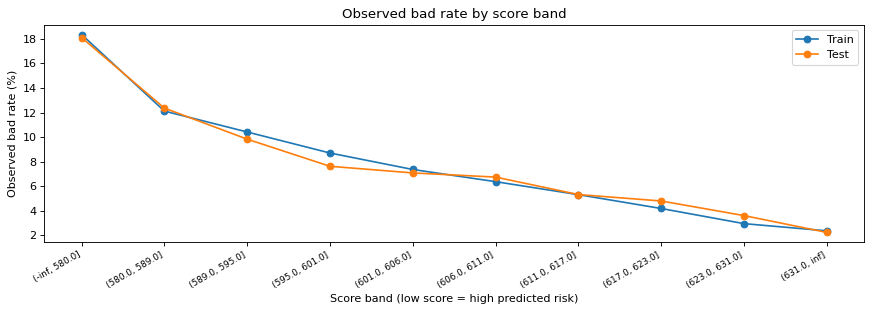

Train: bad rate falls from 18.34% (lowest band) to 2.37% (highest band); falls at every step: True
Test: bad rate falls from 18.09% (lowest band) to 2.24% (highest band); falls at every step: True


In [20]:
_, band_edges = pd.qcut(train['score'], q=10, retbins=True, duplicates='drop')
band_edges[0], band_edges[-1] = -np.inf, np.inf
band_rows = []
for sample, df in [('Train', train), ('Test', test)]:
    g = df.groupby(pd.cut(df['score'], band_edges), observed=True).agg(Applicants=(TARGET, 'size'), Bads=(TARGET, 'sum'))
    g['Bad rate'] = g['Bads'] / g['Applicants']
    g['Sample'] = sample
    band_rows.append(g)
bands = pd.concat(band_rows).reset_index().rename(columns={'score': 'Score band'})
bands['Score band'] = bands['Score band'].astype(str)
order = bands['Score band'].unique()
display(bands.pivot(index='Score band', columns='Sample', values=['Applicants', 'Bad rate']).reindex(order)
        .style.format('{:,.0f}', subset=['Applicants']).format('{:.2%}', subset=['Bad rate']))

fig, ax = plt.subplots(figsize=(11, 4))
for sample, colour in [('Train', 'tab:blue'), ('Test', 'tab:orange')]:
    s = bands[bands['Sample'] == sample]
    ax.plot(range(len(s)), s['Bad rate'] * 100, '-o', color=colour, label=sample)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Observed bad rate (%)'); ax.set_xlabel('Score band (low score = high predicted risk)')
ax.set_title('Observed bad rate by score band'); ax.legend()
plt.tight_layout()
plt.show()

for sample in ['Train', 'Test']:
    rates = bands.loc[bands['Sample'] == sample, 'Bad rate'].values
    print(f'{sample}: bad rate falls from {rates[0]:.2%} (lowest band) to {rates[-1]:.2%} (highest band); falls at every step: {bool(np.all(np.diff(rates) < 0))}')

## 6.11 Model performance on train and test

ROC AUC is the probability that a randomly chosen bad applicant gets a higher predicted PD than a randomly chosen good one. Benchmark:

| AUC | 0.5 - 0.6 | 0.6 - 0.7 | 0.7 - 0.8 | 0.8 - 0.9 | 0.9 - 1.0 |
|---|---|---|---|---|---|
| Discrimination | Not useful | Poor | Fair | Good | Excellent |

We have not used the test sample for any decision so far. A small gap between train and test AUC means the model is not overfitted. Scaling is linear, so the AUC is the same on PDs and on scores.

,Train,Test,Test - Train
ROC AUC (predicted PD),0.6770,0.6697,-0.0073


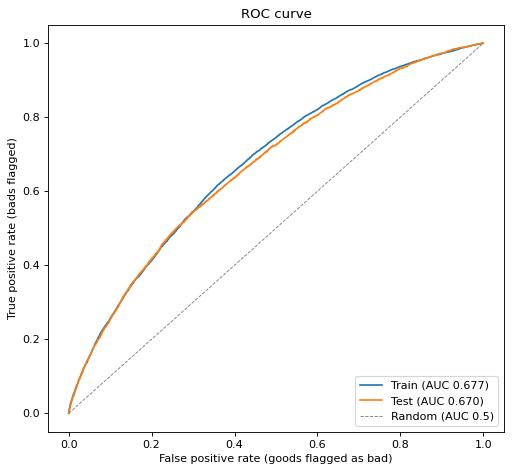

In [21]:
perf = pd.DataFrame({s: {'ROC AUC (predicted PD)': metrics.roc_auc_score(y, p)}
                     for s, y, p in [('Train', y_train, pd_train), ('Test', y_test, pd_test)]})
perf['Test - Train'] = perf['Test'] - perf['Train']
display(perf.style.format('{:.4f}'))

fig, ax = plt.subplots(figsize=(6.5, 6))
for sample, y, p in [('Train', y_train, pd_train), ('Test', y_test, pd_test)]:
    fpr, tpr, _ = metrics.roc_curve(y, p)
    ax.plot(fpr, tpr, label=f'{sample} (AUC {metrics.roc_auc_score(y, p):.3f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=0.8, label='Random (AUC 0.5)')
ax.set_xlabel('False positive rate (goods flagged as bad)'); ax.set_ylabel('True positive rate (bads flagged)')
ax.set_title('ROC curve'); ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**What we found**

AUC is 0.677 on train and 0.670 on test, which is **"Poor" on the benchmark above** (0.6 to 0.7). Goods and bads overlap a lot in score, which fits the weak-to-medium IVs we saw in Step 5. We expected this: the external credit score (`EXT_SOURCE_1`) and age were removed in Step 4, for missingness and fairness.

The train-test gap is only 0.007, so the model is not overfitted. The score bands in 6.10 show the ranking still works: the bad rate falls at every step in both samples, from about 18% in the lowest band to about 2.3% in the highest.

## 6.12 Summary

A summary of our reference-scale scorecard. Step 7 sets the cutoff and final scale.

In [22]:
summary = pd.DataFrame({'Result': {
    'Training / testing applicants': f'{len(train):,} / {len(test):,}',
    'Characteristics in the model': f'{len(MODEL_X)} ({", ".join(MODEL_X)})',
    'Excluded from the regression (coefficient sign)': ', '.join(REMOVED_FOR_SIGN) or 'none',
    'Logistic regression configuration': LR_CONFIG,
    'Logistic regression intercept': f'{lr.intercept_[0]:+.4f}',
    'Reference scale': f'{POINTS0} at 1 : {1 / ODDS0_REFERENCE:.2f}, PDO {PDO}',
    'Score range (train)': f'{train["score"].min():.0f} - {train["score"].max():.0f}',
    'Training AUC': f'{perf.loc["ROC AUC (predicted PD)", "Train"]:.4f}',
    'Testing AUC': f'{perf.loc["ROC AUC (predicted PD)", "Test"]:.4f}',
    'Manual vs sc.scorecard_ply scores': 'identical for all 3 applicants' if (verification['Difference'] == 0).all() else 'differences found',
}})
display(summary)
print(formula)

,Result
Training / testing applicants,"149,318 / 63,994"
Characteristics in the model,"11 (EMPLOYMENT_YEARS, CREDIT_TO_GOODS_RATIO, ACTIVE_LOAN_RATIO, MOST_RECENT_CREDIT_AGE, OCCUPATION_TYPE, OLDEST_CRED..."
Excluded from the regression (coefficient sign),BUREAU_DEBT_TO_INCOME
Logistic regression configuration,Standard
Logistic regression intercept,-2.4491
Reference scale,"600 at 1 : 11.56, PDO 20"
Score range (train),543 - 664
Training AUC,0.6770
Testing AUC,0.6697
Manual vs sc.scorecard_ply scores,identical for all 3 applicants


Logit(PD) = -2.4491
            +0.6787 x EMPLOYMENT_YEARS_woe
            +0.8300 x CREDIT_TO_GOODS_RATIO_woe
            +0.3213 x ACTIVE_LOAN_RATIO_woe
            +0.3766 x MOST_RECENT_CREDIT_AGE_woe
            +0.4526 x OCCUPATION_TYPE_woe
            +0.3806 x OLDEST_CREDIT_AGE_woe
            +0.5701 x ACTIVE_LOAN_COUNT_woe
            +0.2485 x NAME_INCOME_TYPE_woe
            +0.8112 x DEBT_TO_CREDIT_RATIO_woe
            +0.8363 x NAME_EDUCATION_TYPE_woe
            +0.2207 x MICROLOAN_COUNT_woe


## 6.13 Save the model for Step 7

In `07_scorecard analysis.ipynb` we pick the cutoff and final scale, and it has to use this exact model. So we save the bins, the fitted logistic regression, the reference-scale scorecard and its parameters to `data/step6_scorecard_model.pkl`. Step 7 loads these and does not refit anything.

In [23]:
import pickle

ids = pd.concat([train[ID], test[ID]]).values
step6 = {
    'bins': bins, 'lr': lr, 'card': card, 'LR_CONFIG': LR_CONFIG, 'configs': configs,
    'X_COLS': X_COLS, 'MODEL_X': MODEL_X, 'REMOVED_FOR_SIGN': REMOVED_FOR_SIGN, 'breaks_list': breaks_list, 'formula': formula, 'coefficients': coefficients, 'perf': perf,
    'POINTS0': POINTS0, 'PDO': PDO, 'ODDS0_REFERENCE': ODDS0_REFERENCE, 'TARGET_BAD_RATE': TARGET_BAD_RATE,
    'pd_12': pd.Series(np.concatenate([pd_train, pd_test]), index=ids),
    'score_reference': pd.Series(np.concatenate([train['score'].values, test['score'].values]), index=ids),
}
with open('data/step6_scorecard_model.pkl', 'wb') as f:
    pickle.dump(step6, f)
print('Saved data/step6_scorecard_model.pkl:', ', '.join(step6))

Saved data/step6_scorecard_model.pkl: bins, lr, card, LR_CONFIG, configs, X_COLS, MODEL_X, REMOVED_FOR_SIGN, breaks_list, formula, coefficients, perf, POINTS0, PDO, ODDS0_REFERENCE, TARGET_BAD_RATE, pd_12, score_reference
